In this notebook we demonstrate how to import the data and perform some exploratory data analysis in an attempt to identify features which are relevant to our modeling goals

In [69]:
from bs4 import BeautifulSoup, Comment
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

import requests
import time
import csv
from io import StringIO

import sys
from pathlib import Path

In [70]:
pd.set_option('display.max_columns', None)

ROOT = Path.cwd()
while not (ROOT / ".git").exists() and ROOT != ROOT.parent:
     ROOT = ROOT.parent
src_path = str(ROOT/"src")
if src_path not in sys.path:
    sys.path.insert(0,src_path)

from config import START_YEAR, END_YEAR, BASE_URL, HTTP_HEADER
import utils

### [Basketball-Reference Bot Policy](https://www.sports-reference.com/bot-traffic.html)

Basketball reference enforces a 1 day block if you are caught accessing the site more than 20 times a second.  All cells that run loops which collect the data should have `time.sleep(x)` in the loop where x $\geq3$.  In what follows we use `time.sleep(3.3)` for good measure.  Currently the cell should take about 8 minutes to run.

#### IF CHANGES HAVE BEEN MADE TO `utils.scrape_per_game_tables()` YOU NEED TO RESTART THE KERNEL, UNCOMMENT THIS CELL, AND RUN ALL.  DON'T FORGET TO RE-COMMENT OUT THIS CELL IF YOU HAVE ALREADY DOWNLOADED THE DATA AND NO CHANGES HAVE BEEN MADE TO `utils.scrape_per_game_tables()` OR YOU WILL BE SAD WHEN YOU RERUN THE NOTEBOOK!

In [71]:
# utils.scrape_per_game_tables(START_YEAR,END_YEAR)

when we import the datafram from the csv it is important to add a comment keyword or it will mislabel the columns using the descriptive comment instead of the names.

Example for the 2025-2026 season

In [72]:
season = '2025-2026'
df = pd.read_csv(str(ROOT)+f'/data/{season}_season/per_game_stats_{season}.csv',encoding='utf-8',comment='#')

In [73]:
df.sort_values('MVP', ascending=False)

,Year,W%,Code,Player,Age,Team,Pos,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,MVP
1,2025,0.780488,gilgesh01,Shai Gilgeous-Alexander,27.0,OKC,PG,68.0,68.0,33.2,10.8,19.4,0.553,1.7,4.4,0.386,9.1,15.0,0.602,0.597,7.9,9.0,0.879,0.6,3.7,4.3,6.6,1.4,0.8,2.2,2.0,31.1,0.939
7,2025,0.658537,jokicni01,Nikola Jokić,30.0,DEN,C,65.0,65.0,34.8,9.9,17.4,0.569,1.7,4.5,0.380,8.2,12.9,0.636,0.618,6.1,7.4,0.831,3.0,9.9,12.9,10.7,1.4,0.8,3.7,2.7,27.7,0.634
16,2025,0.756098,wembavi01,Victor Wembanyama,22.0,SAS,C,64.0,55.0,29.2,8.6,16.9,0.512,1.9,5.5,0.349,6.7,11.4,0.590,0.569,5.8,7.0,0.827,2.0,9.5,11.5,3.1,1.0,3.1,2.4,2.4,25.0,0.569
0,2025,0.646341,doncilu01,Luka Dončić,26.0,LAL,PG,64.0,64.0,35.8,10.8,22.8,0.476,4.0,10.8,0.366,6.9,11.9,0.575,0.563,7.9,10.1,0.780,0.6,7.1,7.7,8.3,1.6,0.5,4.0,2.4,33.5,0.250
20,2025,0.731707,cunnica01,Cade Cunningham,24.0,DET,PG,64.0,64.0,33.9,8.6,18.6,0.461,2.0,5.7,0.342,6.6,12.9,0.514,0.513,4.8,6.0,0.812,0.9,4.7,5.5,9.9,1.4,0.8,3.7,3.1,23.9,0.117
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,2025,0.506186,huertke01,Kevin Huerter,27.0,2TM,SF,69.0,14.0,22.4,3.9,8.6,0.451,1.4,4.7,0.308,2.4,3.9,0.624,0.535,0.8,1.0,0.775,0.5,3.0,3.5,2.6,0.9,0.5,1.0,1.7,10.0,0.000
252,2025,0.378049,huertke01,Kevin Huerter,27.0,CHI,SF,44.0,11.0,23.6,4.2,9.2,0.455,1.6,5.1,0.314,2.6,4.1,0.630,0.542,0.9,1.3,0.732,0.5,3.3,3.8,2.6,0.8,0.6,1.1,1.9,10.9,0.000
253,2025,0.731707,huertke01,Kevin Huerter,27.0,DET,SG,25.0,3.0,20.5,3.4,7.7,0.443,1.2,4.1,0.294,2.2,3.6,0.611,0.521,0.6,0.6,0.933,0.4,2.4,2.8,2.5,1.1,0.3,0.9,1.2,8.6,0.000
254,2025,0.512195,millejo02,Jordan Miller,26.0,LAC,SF,60.0,1.0,22.1,3.5,6.7,0.531,0.6,1.8,0.345,2.9,4.8,0.602,0.579,2.3,2.9,0.777,0.8,2.2,3.0,2.3,0.8,0.2,1.1,1.0,10.0,0.000


Note that players who have been traded during the season show up multiple times.  One for each team as well as an aggregate row where the team is listed as "#TM" and # is the number of teams they have been on. We have made the team wins/losses for these rows NaNs.  Here are the people who were on three teams.

In [74]:
df.loc[df['Team']=='3TM']

,Year,W%,Code,Player,Age,Team,Pos,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,MVP
428,2025,0.417187,anderky01,Kyle Anderson,32.0,3TM,SF,43.0,5.0,19.8,2.5,4.7,0.530,0.1,0.3,0.364,2.4,4.4,0.539,0.540,1.1,1.6,0.706,1.0,2.5,3.5,2.9,1.0,0.6,0.9,2.2,6.2,0.0
530,2025,0.306313,dennira01,RayJ Dennis,24.0,3TM,PG,17.0,0.0,12.1,1.5,4.9,0.313,0.8,2.6,0.311,0.7,2.2,0.316,0.398,0.5,0.5,0.889,0.5,1.1,1.5,1.9,0.2,0.2,1.0,1.2,4.4,0.0
577,2025,0.353659,baldwpa01,Patrick Baldwin Jr.,23.0,3TM,SF,9.0,1.0,11.3,1.2,3.0,0.407,0.7,1.6,0.429,0.6,1.4,0.385,0.519,0.6,0.8,0.714,1.3,1.2,2.6,0.6,0.3,0.6,0.6,1.7,3.7,0.0
618,2025,0.539134,jonesty01,Tyus Jones,29.0,3TM,PG,67.0,12.0,14.6,1.1,3.3,0.349,0.6,2.0,0.292,0.5,1.2,0.444,0.440,0.1,0.1,0.778,0.2,1.0,1.1,2.4,0.6,0.0,0.4,0.5,3.0,0.0
641,2025,0.462963,kolokch01,Christian Koloko,25.0,3TM,C,27.0,4.0,13.2,1.1,2.7,0.419,0.0,0.3,0.111,1.1,2.4,0.462,0.426,0.4,0.6,0.667,1.1,1.9,3.0,0.7,0.5,0.9,0.6,1.8,2.7,0.0


Now we import all of the data into a single pandas dataframe

In [75]:
df_tot = utils.player_stat_dataframe(START_YEAR,END_YEAR)

In [76]:
df_tot.sample(10)

,Year,W%,Code,Player,Age,Team,Pos,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,MVP
8610,1999,0.634146,cartean01,Anthony Carter,24.0,MIA,PG,79.0,30.0,23.5,2.5,6.4,0.395,0.0,0.3,0.130,2.5,6.2,0.407,0.398,1.2,1.6,0.750,0.6,1.9,2.5,4.8,1.2,0.1,2.2,2.1,6.3,0.0
7369,1997,0.320624,jacksji01,Jim Jackson,27.0,2TM,SG,79.0,78.0,38.6,6.0,14.0,0.430,0.8,2.4,0.319,5.3,11.6,0.453,0.458,2.9,3.6,0.812,1.6,3.4,5.1,4.8,1.0,0.1,3.3,2.4,15.7,0.0
10468,2003,0.439024,davisri01,Ricky Davis,24.0,BOS,SF,57.0,5.0,29.4,5.5,11.2,0.488,0.6,1.6,0.380,4.9,9.6,0.506,0.516,2.5,3.5,0.732,1.0,3.1,4.2,2.6,1.2,0.2,2.1,2.1,14.1,0.0
9543,2001,0.743902,turkohe01,Hedo Türkoğlu,22.0,SAC,SF,80.0,10.0,24.6,3.6,8.6,0.422,0.8,2.1,0.368,2.8,6.5,0.440,0.468,2.1,2.9,0.726,0.8,3.8,4.5,2.0,0.7,0.4,1.0,2.3,10.1,0.0
14076,2009,0.390244,headlu01,Luther Head,27.0,IND,SG,47.0,10.0,17.3,2.9,6.6,0.437,0.8,2.2,0.352,2.1,4.4,0.481,0.497,1.0,1.2,0.828,0.1,1.6,1.7,1.5,0.4,0.2,1.1,1.1,7.6,0.0
7722,1997,0.507012,simpkdi01,Dickey Simpkins,25.0,2TM,PF,40.0,0.0,10.8,1.2,2.2,0.539,0.0,0.1,0.000,1.2,2.2,0.552,0.539,0.9,1.8,0.514,0.7,1.3,1.9,0.8,0.2,0.1,0.8,1.4,3.3,0.0
24437,2025,0.317073,chrisma02,Max Christie,22.0,DAL,SG,77.0,68.0,29.1,4.2,9.4,0.441,2.3,5.8,0.404,1.8,3.6,0.502,0.566,1.6,1.8,0.899,0.2,3.0,3.2,2.0,0.6,0.4,1.2,1.3,12.3,0.0
20125,2019,0.611111,adamsst01,Steven Adams,26.0,OKC,C,63.0,63.0,26.7,4.5,7.6,0.592,0.0,0.0,0.333,4.5,7.5,0.594,0.593,1.9,3.2,0.582,3.3,6.0,9.3,2.3,0.8,1.1,1.5,1.9,10.9,0.0
21910,2021,0.585671,hernaju01,Juancho Hernangómez,26.0,3TM,PF,40.0,9.0,11.1,1.1,2.7,0.415,0.6,1.7,0.348,0.5,0.9,0.541,0.528,0.5,0.9,0.559,0.7,1.8,2.5,0.5,0.4,0.3,0.4,0.6,3.3,0.0
22623,2022,0.658537,thybuma01,Matisse Thybulle,25.0,PHI,SF,49.0,6.0,12.1,1.0,2.4,0.431,0.4,1.3,0.333,0.6,1.1,0.547,0.522,0.2,0.2,0.750,0.4,0.9,1.3,0.5,0.9,0.3,0.2,1.3,2.7,0.0


In [77]:
df_mvp = df_tot.loc[df_tot['MVP'] != 0.0].reset_index(drop=True)
df_mvp.sample(5)

df_new = df_tot.copy()
df_new['RecievedVotes'] = (df_tot['MVP'] != 0.0).astype('int64')
df_new['TradedMidSeason'] = df_tot['Team'].str.endswith('TM').groupby([df_tot['Year'], df_tot['Code']]).transform('any').astype('int64') #adding a col to show of a player got traded

In [78]:
features = df_mvp.drop(columns=['Year','Code','Player','Team','Pos','Age','FG%','3P%', '2P%', 'FT%', 'FGA', '3PA', '2PA', 'FTA', 'PF']).columns[:-1]
target = df_mvp.columns[-1]

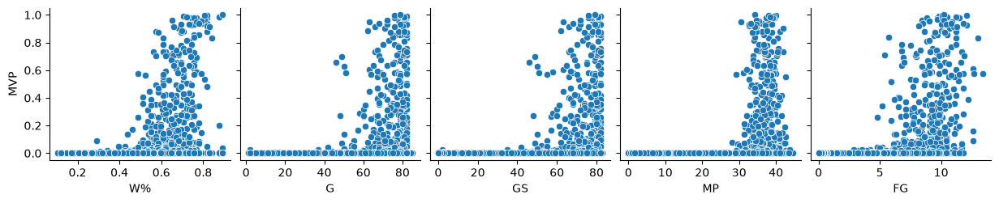

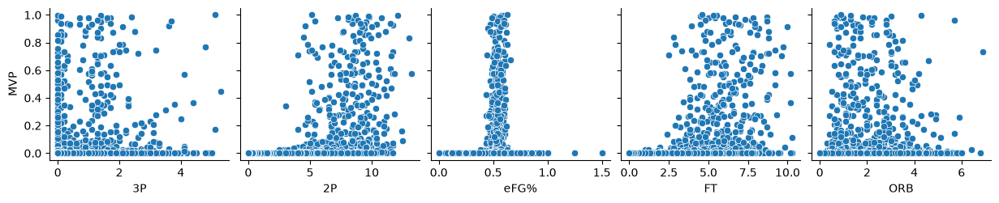

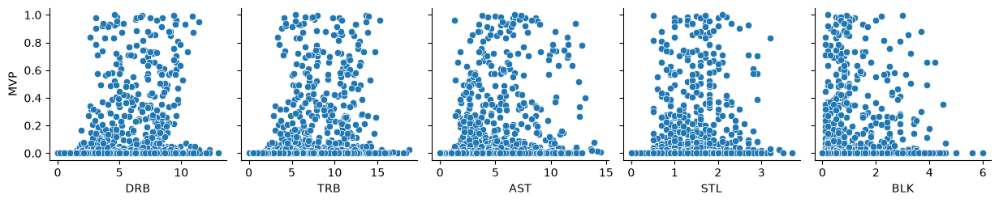

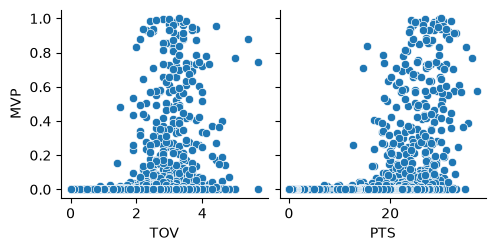

In [79]:
for i in range(0,len(features),5):
    sns.pairplot(
        df_tot,
        x_vars=features[i:i+5],
        y_vars=target,
    )
    plt.show()

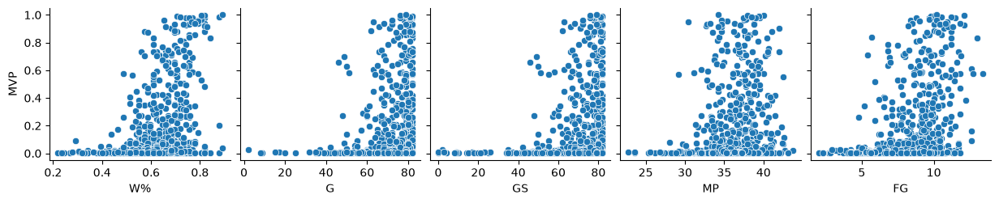

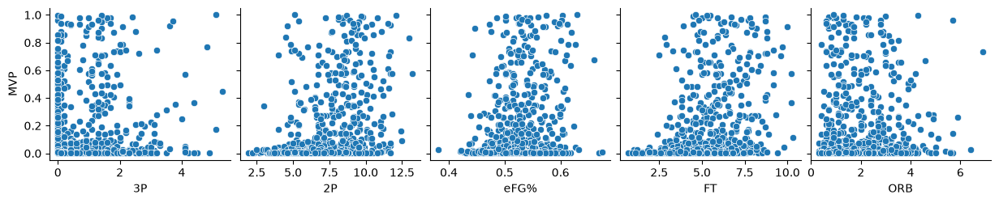

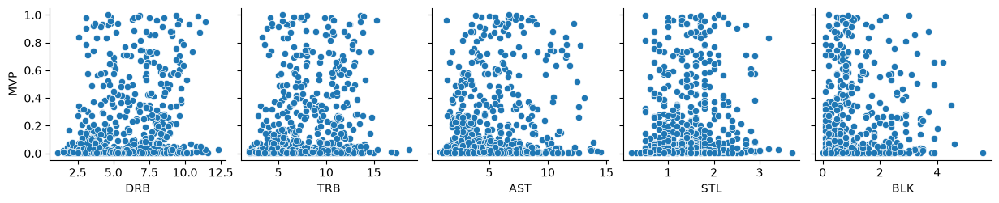

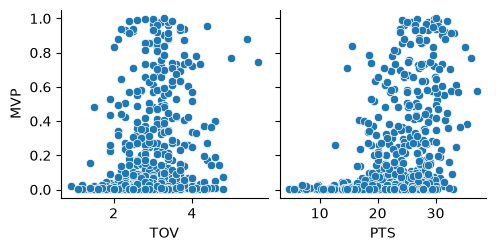

In [80]:
for i in range(0,len(features),5):
    sns.pairplot(
        df_mvp,
        x_vars=features[i:i+5],
        y_vars=target,
    )
    plt.show()

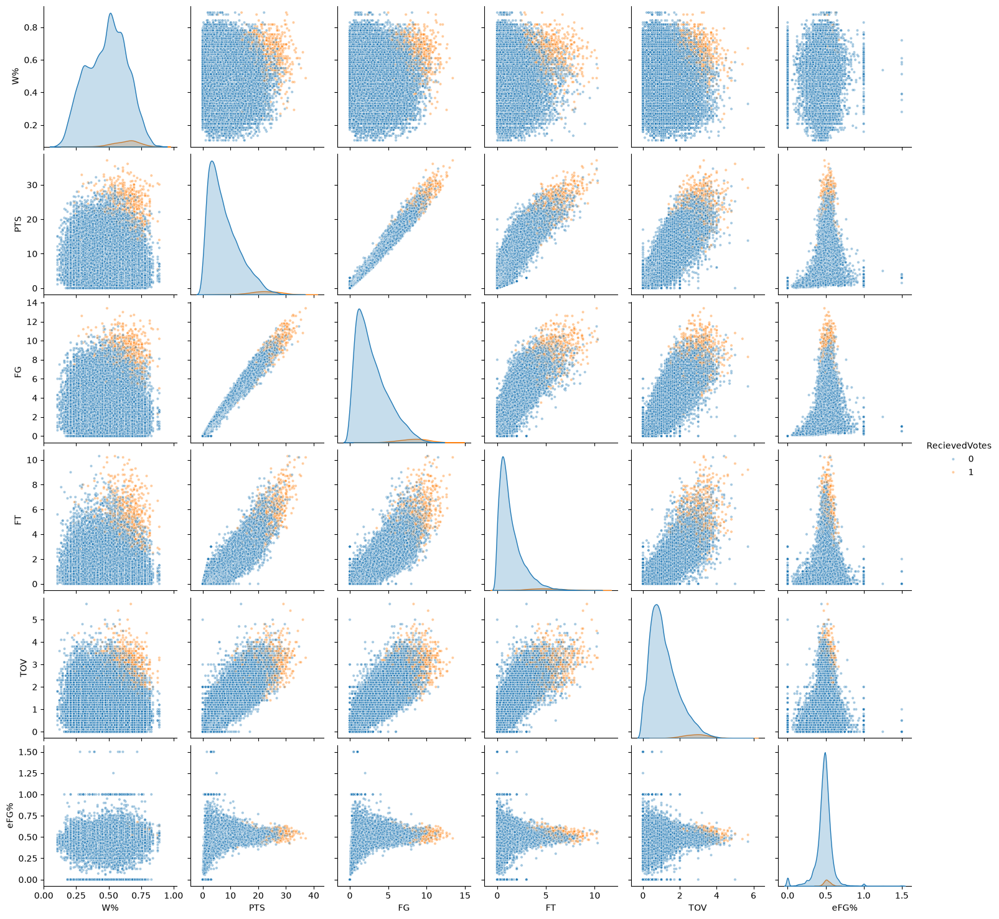

In [81]:
# checking some hand-chosen features

custom_palette = {
    0: (0.12, 0.47, 0.71, 0.4),  # Light blue
    1: (1.00, 0.50, 0.05, 0.4)   # Light orange
}
sns.pairplot(
    df_new,
    x_vars=['W%','PTS','FG','FT','TOV','eFG%'],
    y_vars=['W%','PTS','FG','FT','TOV','eFG%'],
    hue='RecievedVotes',
    plot_kws={"s":10},
    palette=custom_palette
)
plt.show()

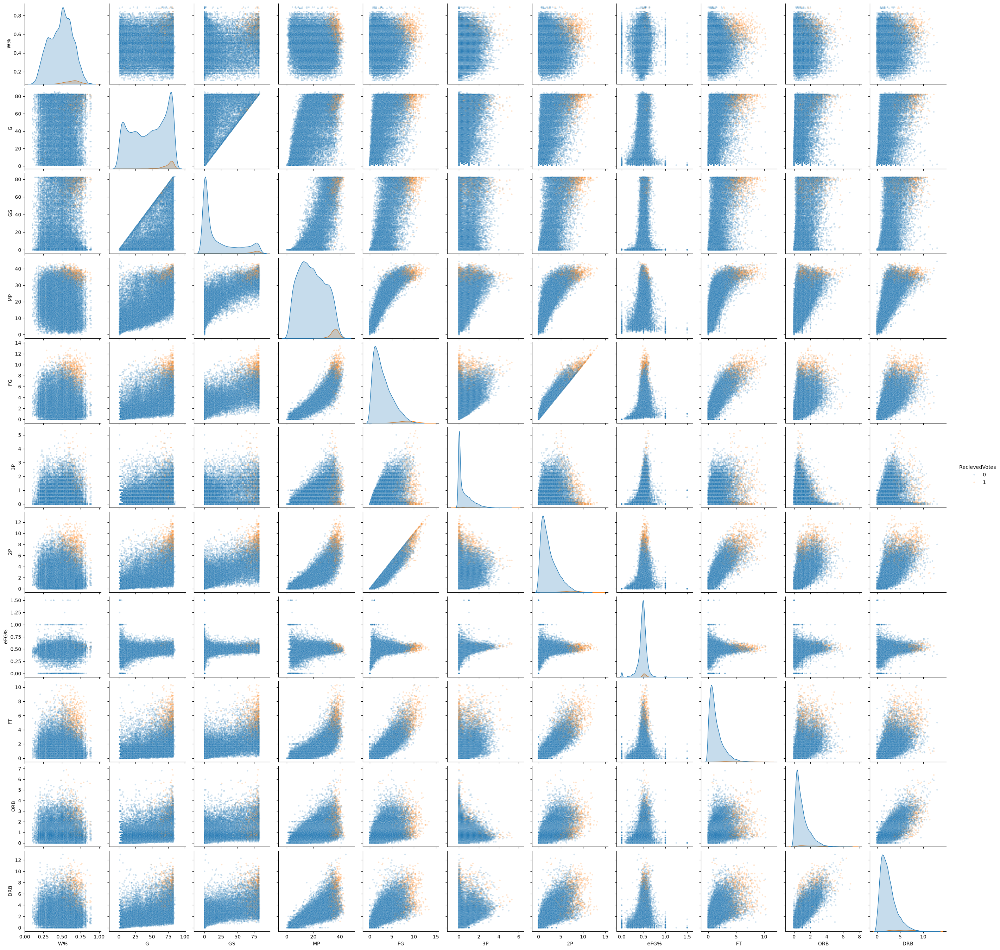

In [82]:
sns.pairplot(
    df_new,
    x_vars=features[0:11],
    y_vars=features[0:11],
    hue='RecievedVotes',
    plot_kws={"alpha": 0.2,"s":10}
)
plt.show()

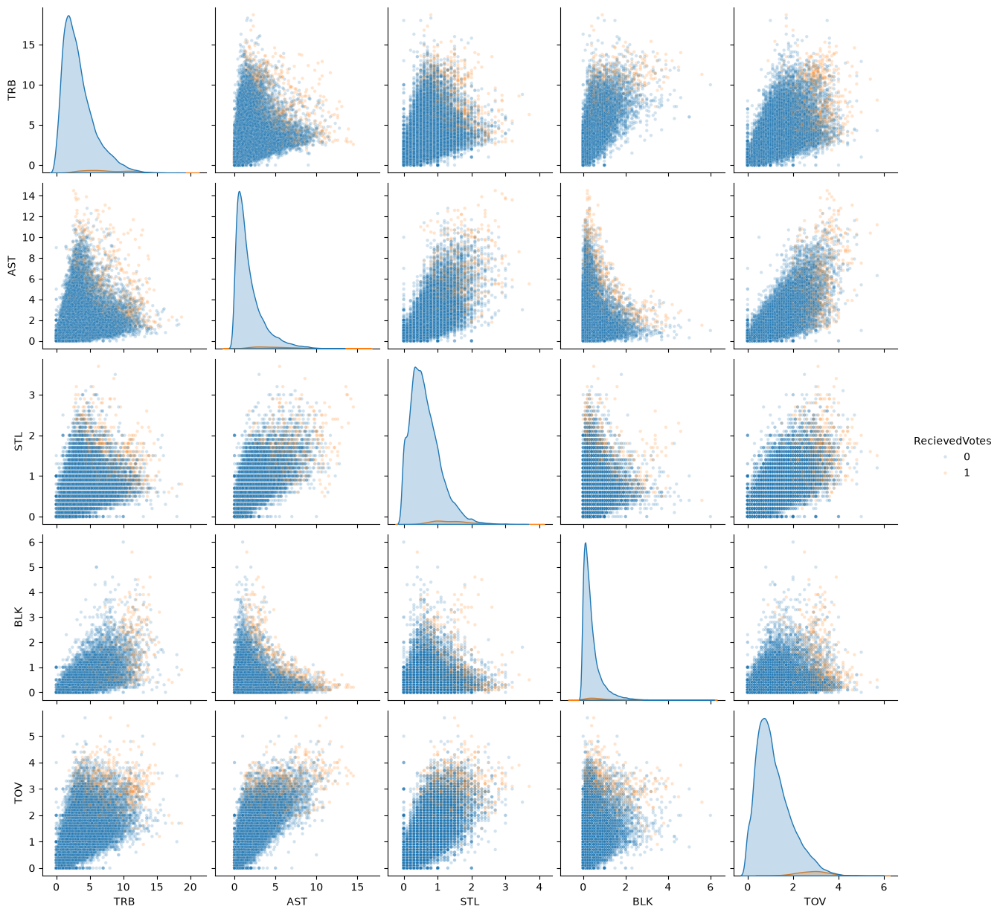

In [83]:
sns.pairplot(
    df_new,
    x_vars=features[11:-1],
    y_vars=features[11:-1],
    hue='RecievedVotes',
    plot_kws={"alpha": 0.2,"s":10}
)
plt.show()

In [84]:
print(features)
X = df_new[features]
y = df_new['RecievedVotes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, predictions))

Index(['W%', 'G', 'GS', 'MP', 'FG', '3P', '2P', 'eFG%', 'FT', 'ORB', 'DRB',
       'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PTS'],
      dtype='str')
Model Accuracy: 98.44%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      4853
           1       0.85      0.56      0.68       146

    accuracy                           0.98      4999
   macro avg       0.92      0.78      0.83      4999
weighted avg       0.98      0.98      0.98      4999



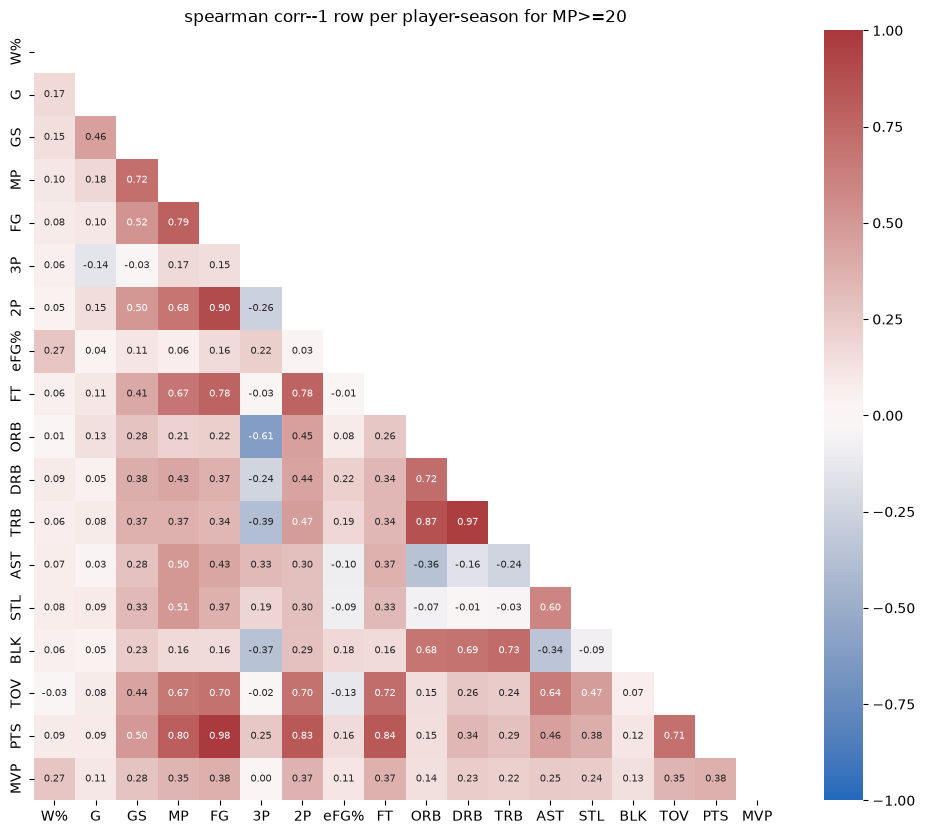

In [85]:
#heatmap to see correlations
season_rows=df_new[(df_new['TradedMidSeason']==0) | df_new['Team'].str.endswith('TM')]
rel=season_rows[(season_rows['MP']>=20) & (season_rows['G']>=20)]

corr=rel[list(features) + ['MVP']].corr(method='spearman')
mask=np.triu(np.ones_like(corr,dtype=bool))
plt.figure(figsize=(12,10))
sns.heatmap(corr,mask=mask,cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',annot_kws={'size':7})
plt.title('spearman corr--1 row per player-season for MP>=20')
plt.show()

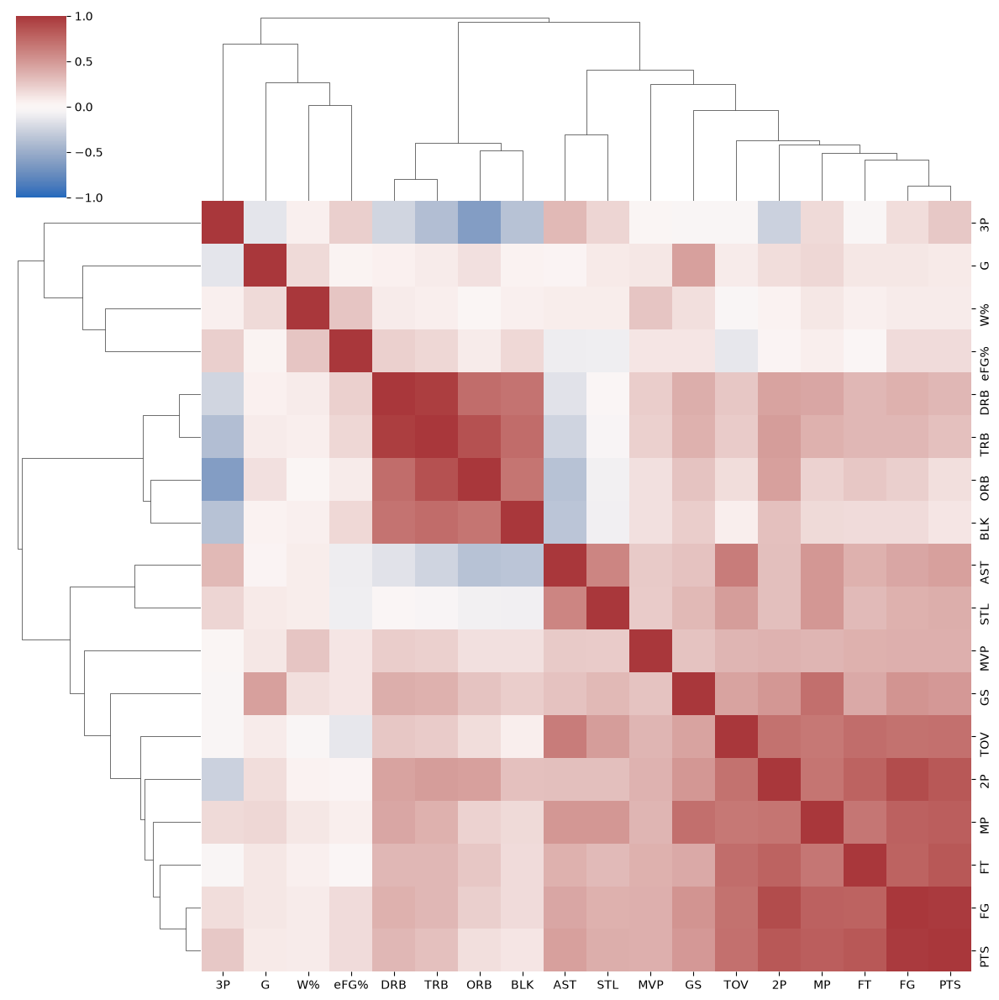

In [88]:
#clustering groups features whose rows in heatmap look alike, meaning they correlate with evything else in a similar way. So for feature selection we move up the tree from the leaves and when we hit a group we keep on representative
sns.clustermap(corr,cmap='vlag',center=0,vmin=-1,vmax=1,figsize=(12,12))
plt.show()

the heatmap and clustermap give some sense of stars vs bench players and a big play time effect.

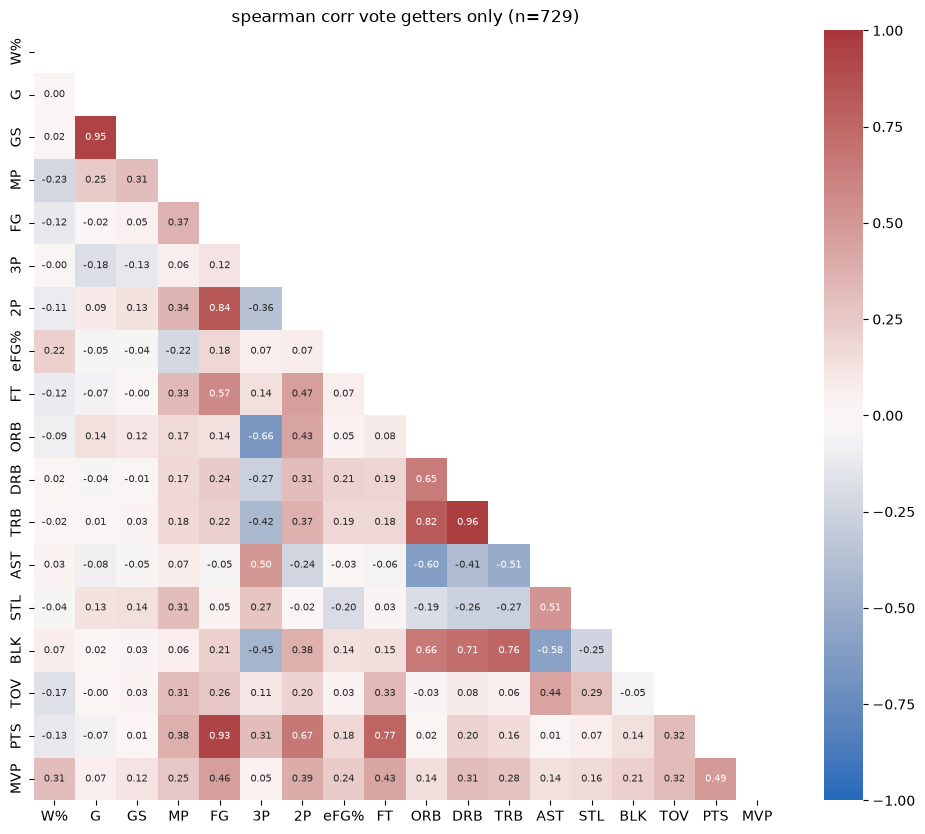

In [87]:
#addressing my question of finding out among players good enough to get votes, what separates the winner from the rest
vg=rel[rel['MVP']>0]
corr_vg=vg[list(features)+['MVP']].corr(method='spearman')
mask=np.triu(np.ones_like(corr_vg,dtype=bool))
plt.figure(figsize=(12,10))
sns.heatmap(corr_vg,mask=mask,cmap='vlag',center=0,vmin=-1,vmax=1,annot=True,fmt='.2f',annot_kws={'size':7})
plt.title(f'spearman corr vote getters only (n={len(vg)})')
plt.show()

this heatmap give a sense of what separates MVP players from each other.  Considering it we focus in on the following features to begin with:
```
feats=['PTS','W%','FT','eFG%','DRB','AST','BLK','STL','GS','3P']
```